In [17]:
import numpy as np
from experiments_utils import ICS26_DIR

TF = 5.0
DT = 0.2
tvec = np.arange(0, TF+DT, DT)

# Load data
directory = ICS26_DIR / 'lorenz_successive_timestep_data'
trajectories = np.load(directory / 'trajectory_data.npz')
yvec_exact = trajectories['exact']
yvec_surrogate = trajectories['surrogate']
N_timesteps, N_trajectories, dim = yvec_surrogate.shape


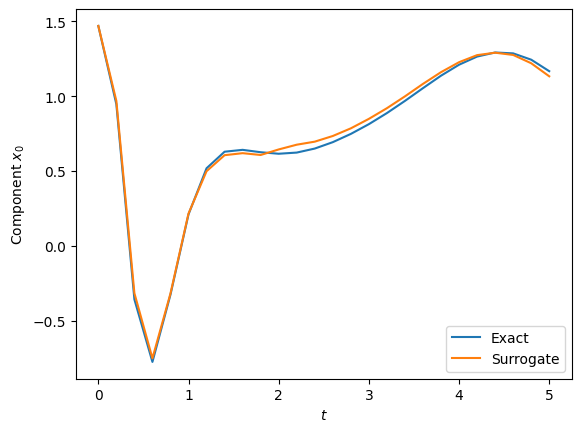

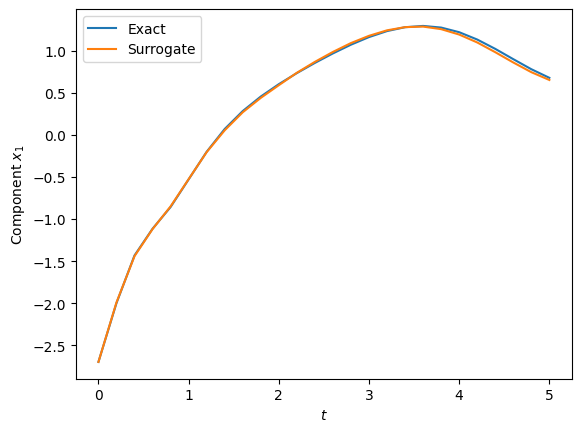

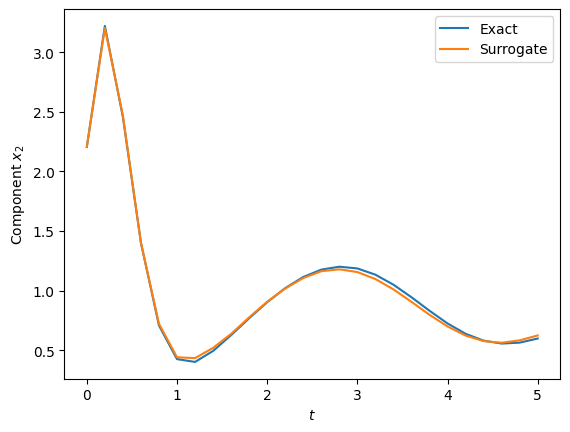

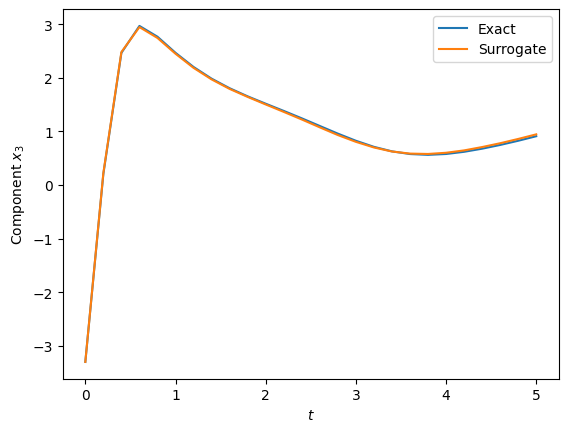

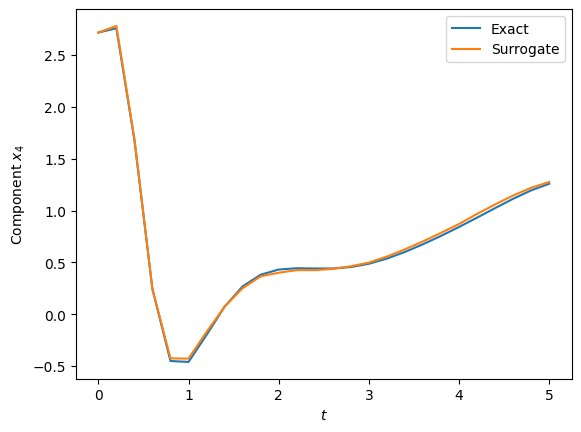

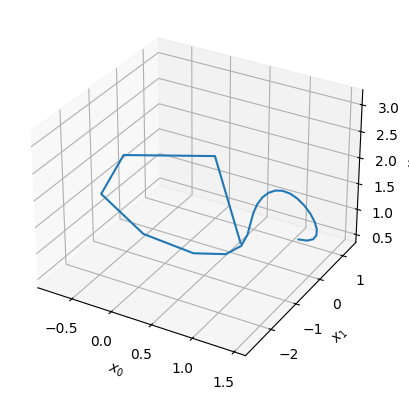

In [18]:
# Pick specific trajectory
trajectory = 15
yvec_exact_onetraj = yvec_exact[:,trajectory,:]
yvec_surrogate_onetraj = yvec_surrogate[:,trajectory,:]

# Generate plots
import matplotlib.pyplot as plt

# Component 1
for i in range(dim):
    fig = plt.figure()
    ax = fig.add_subplot()

    ax.plot(tvec, yvec_exact_onetraj[:,i], label='Exact')
    ax.plot(tvec, yvec_surrogate_onetraj[:,i], label='Surrogate')

    ax.set_xlabel("$t$")
    ax.set_ylabel(f"Component $x_{i}$")

    plt.legend()
    plt.show()

fig = plt.figure()
ax = fig.add_subplot(projection='3d')

ax.plot(yvec_exact_onetraj[:,0], yvec_exact_onetraj[:,1], yvec_exact_onetraj[:,2])
ax.set_xlabel('$x_0$')
ax.set_ylabel('$x_1$')
ax.set_zlabel('$x_2$')
plt.show()

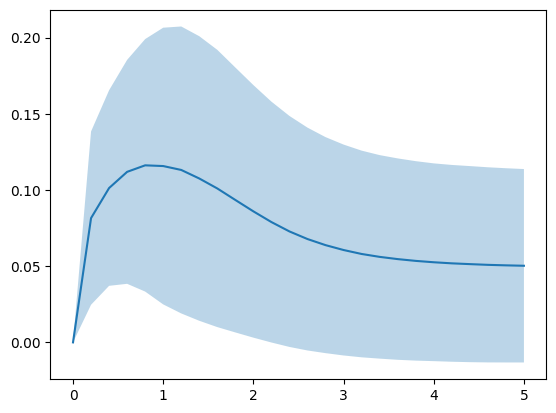

In [21]:
yvec_error = yvec_exact - yvec_surrogate

# For each time step, for each trajectory, compute distances
distances = np.linalg.norm(yvec_error, ord=2, axis=2) # flatten along output dim
# Compute mean and standard deviation for each time step
means = np.mean(distances, axis=1)
stds = np.std(distances, axis=1)

# Plot
fig, ax = plt.subplots()
ax.plot(tvec, means)
ax.fill_between(tvec, means + stds, means - stds, alpha=0.3)


